In [1]:
import torch


### Setting up GPU


In [2]:
device = (
    torch.accelerator.current_accelerator().type
    if torch.accelerator.is_available()
    else "cpu"
)
torch.set_default_device(device)
print("Using device: ", torch.get_default_device())


Using device:  mps:0


### Preparing the data

In [3]:
# preparing the data

import string
import unicodedata

# "_" to represent an out-of-vocabulary character
allowed_char = string.ascii_letters + " .,;" + "_"
n_letters = len(allowed_char)


def unicode_to_ascii(s):
    return "".join(
        c
        for c in unicodedata.normalize("NFD", s)
        if unicodedata.category(c) != "Mn" and c in allowed_char
    )


print("Number of allowed_char =", n_letters)
print("Allowed Characters are :", allowed_char)


Number of allowed_char = 57
Allowed Characters are : abcdefghijklmnopqrstuvwxyzABCDEFGHIJKLMNOPQRSTUVWXYZ .,;_


In [4]:
print(f"Converting Escárcega to {unicode_to_ascii('Escárcega')}")


Converting Escárcega to Escarcega


### Turning names into tensor


In [5]:
# Find letter index from all_letters, e.g. "a" = 0
def letter_to_index(letter):
    # map out-of-vocab char to '_'
    if letter not in allowed_char:
        return allowed_char.find("_")
    return allowed_char.find(letter)


# Turn a line into a <line_length x 1 x n_letters>,
# or an array of one-hot letter vectors
def line_to_tensor(line):
    tensor = torch.zeros(len(line), 1, n_letters)
    for li, letter in enumerate(line):
        tensor[li][0][letter_to_index(letter)] = 1

    return tensor


In [6]:
print("Line to Tensor:")
print("Abalihin = ", line_to_tensor("Abalihin"))
print(line_to_tensor("Abalihin").shape)


Line to Tensor:
Abalihin =  tensor([[[0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0.]],

        [[0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0.]],

        [[1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0.]],

        [[0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
   

### Dataset

In [7]:
import glob
import os
import time
from io import open

from torch.utils.data import Dataset


class NamesDataset(Dataset):
    def __init__(self, data_dir):
        super().__init__()
        self.data_dir = data_dir
        self.load_time = time.localtime
        labels_set = set()  # set of all classes

        self.data = []
        self.data_tensor = []
        self.labels = []
        self.labels_tensor = []

        # read all the ``.txt`` files in the specified directory
        text_files = glob.glob(os.path.join(data_dir, "*.txt"))
        for filename in text_files:
            label = os.path.splitext(os.path.basename(filename))[0]
            labels_set.add(label)

            lines = open(filename, encoding="utf-8").read().strip().split("\n")
            for name in lines:
                self.data.append(name)
                self.data_tensor.append(line_to_tensor(name))
                self.labels.append(label)

        # tensor representation of the labels
        self.labels_uniq = sorted(labels_set)
        for index in range(len(self.labels)):
            temp_tensor = torch.tensor(
                [self.labels_uniq.index(self.labels[index])], dtype=torch.long
            )
            self.labels_tensor.append(temp_tensor)

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        data_item = self.data[idx]
        data_label = self.labels[idx]
        data_tensor = self.data_tensor[idx]
        label_tensor = self.labels_tensor[idx]

        return label_tensor, data_tensor, data_item, data_label


In [8]:
alldata = NamesDataset("char_rnn_data/names")
print(f"loaded {len(alldata)} items of data")
print(f"example = {alldata[0]}")


loaded 20074 items of data
example = (tensor([2], device='mps:0'), tensor([[[0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0.]],

        [[0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0.]],

        [[0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0.]]], device='mps:0'), 'Abl', 'Czech')


In [9]:
# train and test split 85 - 15

train_set, test_set = torch.utils.data.random_split(
    alldata, [0.85, 0.15], generator=torch.Generator(device=device).manual_seed(2024)
)
print(f"train examples = {len(train_set)}, validation examples = {len(test_set)}")


train examples = 17063, validation examples = 3011


### Creating the Network

In [10]:
from torch import nn


class CharRNN(nn.Module):
    def __init__(self, input_size, output_size):
        super().__init__()
        self.rnn = nn.RNN(input_size, 128)
        self.linear = nn.Linear(in_features=128, out_features=output_size)
        self.softmax = nn.LogSoftmax(dim=1)

    def forward(self, line_tensor):
        _rnn_out, hidden = self.rnn(line_tensor)
        logits = self.linear(hidden[0])
        output = self.softmax(logits)

        return output


In [11]:
model_rnn = CharRNN(n_letters, len(alldata.labels_uniq)).to(device)
print(model_rnn)


CharRNN(
  (rnn): RNN(57, 128)
  (linear): Linear(in_features=128, out_features=18, bias=True)
  (softmax): LogSoftmax(dim=1)
)


### Label from Output Probabilities

In [12]:
def label_from_output(output, output_labels):
    _top_n, top_i = output.topk(1)
    label_i = top_i[0].item()
    return output_labels[label_i], label_i


input_tensor = line_to_tensor("Albert")
output = model_rnn(
    input_tensor
)  # this is equivalent to ``output = rnn.forward(input)``
print(output)
print(label_from_output(output, alldata.labels_uniq))


tensor([[-2.8786, -2.9214, -2.9016, -2.9090, -2.8890, -2.9087, -2.8245, -2.8440,
         -2.8887, -3.0422, -2.9238, -2.8952, -2.9141, -2.9361, -2.7563, -2.9219,
         -2.8832, -2.8180]], device='mps:0', grad_fn=<LogSoftmaxBackward0>)
('Russian', 14)


### Training

In [13]:
import random

import numpy as np


def train(
    model,
    training_data,
    n_epochs,
    n_batch_size,
    report_every,
    criterion,
    learning_rate=0.02,
):

    # set train mode
    model.train()

    # track loss for plotting
    all_losses = []
    current_loss = 0

    # optimizer
    optimizer = torch.optim.Adam(params=model.parameters(), lr=learning_rate)

    for epoch in range(1, n_epochs + 1):
        # to avoid gradient accumulation
        model.zero_grad()

        batches = list(range(len(training_data)))
        random.shuffle(batches)
        batches = np.array_split(batches, len(training_data) // n_batch_size)

        for _idx, batch in enumerate(batches):
            batch_loss = 0
            for i in batch:
                label_tensor, data_tensor, _data_item, _data_label = training_data[i]
                output = model(data_tensor)
                loss = criterion(output, label_tensor)
                batch_loss += loss

            # optimize parameters
            batch_loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 3)
            optimizer.step()
            optimizer.zero_grad()

            current_loss += batch_loss.item() / len(batch)

        all_losses.append(current_loss / len(batches))

        if epoch % report_every == 0:
            print(
                f"{epoch} ({epoch / n_epochs:.0%}): \t average batch loss = {all_losses[-1]}"
            )
        current_loss = 0

    return all_losses


In [14]:
start = time.time()
all_losses = train(
    model_rnn,
    train_set,
    n_epochs = 50,
    n_batch_size = 16,
    report_every = 6,
    criterion = nn.NLLLoss(),
    learning_rate=0.001)
end = time.time()
print(f"training took {end-start}s")


6 (12%): 	 average batch loss = 0.6722936326667259
12 (24%): 	 average batch loss = 0.49383828123409995
18 (36%): 	 average batch loss = 0.3615959360854836
24 (48%): 	 average batch loss = 0.28073747107847924
30 (60%): 	 average batch loss = 0.22900950325778072
36 (72%): 	 average batch loss = 0.19231210403488455
42 (84%): 	 average batch loss = 0.17666913503058793
48 (96%): 	 average batch loss = 0.15960423627129677
training took 3204.339667081833s


### Plotting the Results

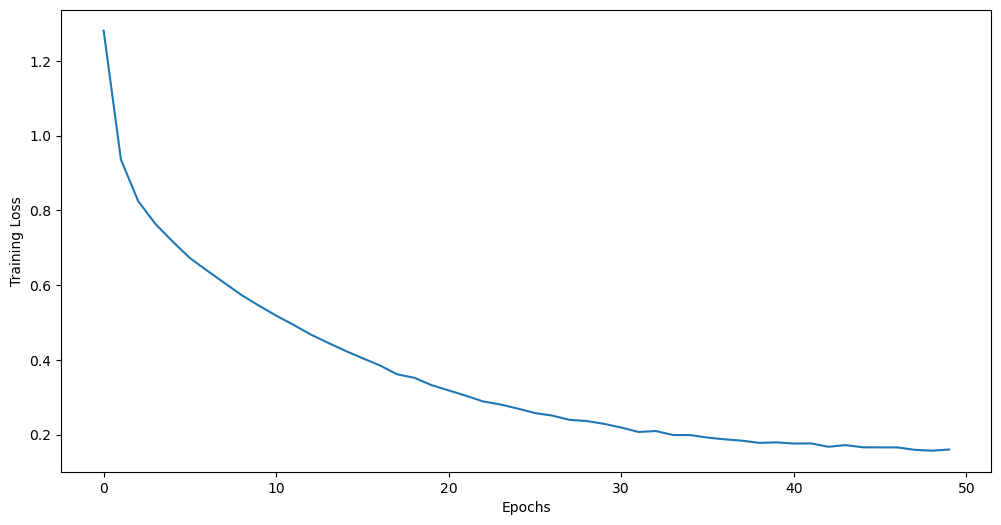

In [15]:
import matplotlib.pyplot as plt
from matplotlib import ticker

plt.figure(figsize=(12,6))
plt.plot(all_losses)
plt.xlabel("Epochs")
plt.ylabel("Training Loss")
plt.show()


### Evaluating the results

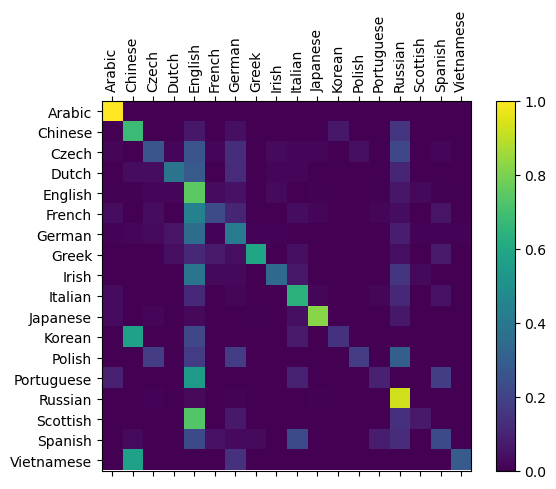

In [16]:
def evaluate(rnn, testing_data, classes):
    confusion = torch.zeros(len(classes), len(classes))

    rnn.eval() #set to eval mode
    with torch.no_grad(): # do not record the gradients during eval phase
        for i in range(len(testing_data)):
            (_label_tensor, text_tensor, _text, label) = testing_data[i]
            output = rnn(text_tensor)
            _guess, guess_i = label_from_output(output, classes)
            label_i = classes.index(label)
            confusion[label_i][guess_i] += 1

    # Normalize by dividing every row by its sum
    for i in range(len(classes)):
        denom = confusion[i].sum()
        if denom > 0:
            confusion[i] = confusion[i] / denom

    # Set up plot
    fig = plt.figure()
    ax = fig.add_subplot(111)
    cax = ax.matshow(confusion.cpu().numpy()) #numpy uses cpu here so we need to use a cpu version
    fig.colorbar(cax)

    # Set up axes
    ax.set_xticks(np.arange(len(classes)), labels=classes, rotation=90)
    ax.set_yticks(np.arange(len(classes)), labels=classes)

    # Force label at every tick
    ax.xaxis.set_major_locator(ticker.MultipleLocator(1))
    ax.yaxis.set_major_locator(ticker.MultipleLocator(1))

    # sphinx_gallery_thumbnail_number = 2
    plt.show()


evaluate(model_rnn, test_set, classes=alldata.labels_uniq)


In [22]:
input_tensor = line_to_tensor("Takaichi")
output = model_rnn(input_tensor)
print(output)
print(label_from_output(output, alldata.labels_uniq))


tensor([[-20.6746, -26.5417, -20.8527, -22.9416, -22.1655, -29.0655, -23.4497,
         -20.6544, -23.5428, -18.2688,   0.0000, -22.1623, -22.9737, -26.5787,
         -16.6516, -26.3623, -27.6523, -25.8081]], device='mps:0',
       grad_fn=<LogSoftmaxBackward0>)
('Japanese', 10)
